<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Open-Meteo Weather](https://github.com/Query-farm/vgi-open-meteo)

Keyless weather forecasts, history, air quality, marine, flood and climate data from Open-Meteo, plus geocoding and elevation.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-open-meteo/blob/main/notebooks/02_weather_codes_and_hourly_selection.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-open-meteo/blob/main/notebooks/README.md)

## Decode the weather, then state the hourly selection rule

How many of Tokyo's next two provider days have a returned daylight flag and modeled wind at or below a chosen limit? Decode weather codes, compass bearings and UV categories without turning them into an unstated recommendation. Keep the current snapshot separate from hourly evidence.

### Make one explicit selection

Edit the parameter, then **Restart Kernel → Run All**. All source calls are live and materialized once per run. These are modeled products, not station observations. Windows begin at the provider's current UTC midnight and can include elapsed hours; acquisition time is not model issuance time.

In [1]:
MAX_WIND_MS = 1.5  # Experiment: 0.75 m/s; an illustrative analytical limit

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.39":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.39"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, prose, theme, finish

check_runtime()
prepare("open-meteo")
import matplotlib.dates as mdates  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
import numpy as np  # noqa: E402
from IPython.display import display  # noqa: E402
from open_meteo_example import PALETTE, weather_window, finite_limit, number  # noqa: E402

theme()

run_started = finite_limit(MAX_WIND_MS, "MAX_WIND_MS", 50)
session = connect(globals())

### Connect the public worker release

The shared `vgi-bun-worker` launcher retrieves the official checksum-verified Bun runtime, verifies release **v0.4.0**, installs its unchanged frozen dependencies once and runs the released TypeScript. It needs Git and an internet connection on first use; it works without a worker checkout or a separately installed Bun. This release has no native assets and its declared npm package is unavailable.

The free API needs no key. Shared setup creates an empty SQL-secret directory; this ATTACH supplies no commercial credential. The UTC SQL session keeps displayed timestamps on one clock.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL icu;
LOAD icu;
SET TimeZone='UTC';
ATTACH 'open_meteo' AS weather (
    TYPE vgi,
    LOCATION 'vgi-bun-worker Query-farm/vgi-open-meteo@v0.4.0'
);

,Success


### Resolve a place and keep the products separate

Review the geocoding candidate before using it. Terrain elevation is a separate lookup at that coordinate; the forecast grid can have different coordinates and elevation. Current conditions summarize a provider interval, whereas the hourly forecast is a sequence. Both are modeled products; neither is a ground-truth observation for scoring the other.

In [5]:
%%sql
CREATE TABLE place AS SELECT * FROM weather.main.geocoding('Tokyo', count:=1);
CREATE TABLE terrain AS SELECT e.* FROM place p,
 LATERAL weather.main.elevation(p.latitude,p.longitude) e;
CREATE TABLE snapshot AS SELECT w.* FROM place p,
 LATERAL weather.main.forecast_current(p.latitude,p.longitude,wind_speed_unit:='ms') w;
CREATE TABLE hours AS SELECT w.* FROM place p,
 LATERAL weather.main.forecast_hourly(p.latitude,p.longitude,forecast_days:=2,
 timezone:='GMT',wind_speed_unit:='ms',temperature_unit:='celsius',precipitation_unit:='mm') w;
CREATE TABLE codes AS SELECT * FROM weather.main.weather_codes;

,Count


In [6]:
%%sql location <<
SELECT p.name,p.country,p.latitude,p.longitude,p.timezone,
 p.elevation AS geocoding_elevation_m,t.elevation AS terrain_elevation_m,
 s.grid_latitude,s.grid_longitude,s.location_elevation AS forecast_elevation_m,
 s.time AS current_time_utc,s.interval_seconds AS current_support_seconds,
 s.retrieved_at AS current_retrieval_utc
FROM place p CROSS JOIN terrain t CROSS JOIN snapshot s;

In [7]:
display(location)
if len(location) != 1 or location.country.iloc[0] != "Japan":
    raise ValueError("Review the place resolution before interpreting Tokyo weather.")
row = location.iloc[0]
prose(f"The terrain lookup returns **{number(row.terrain_elevation_m)} m** and the forecast location **{number(row.forecast_elevation_m)} m**. These describe different source products; their difference is not an elevation error estimate. The current row supports a **{int(row.current_support_seconds)}-second** interval.")

,name,country,latitude,longitude,timezone,geocoding_elevation_m,terrain_elevation_m,grid_latitude,grid_longitude,forecast_elevation_m,current_time_utc,current_support_seconds,current_retrieval_utc
0,Tokyo,Japan,35.6895,139.69171,Asia/Tokyo,44.0,40.0,35.7,139.6875,40.0,2026-11-14 23:45:00+00:00,900,2026-11-14 23:51:30.310000+00:00


The terrain lookup returns **40.0 m** and the forecast location **40.0 m**. These describe different source products; their difference is not an elevation error estimate. The current row supports a **900-second** interval.

### Retain codes beside their readable labels

The `weather_codes` relation and decoding macros describe the same released lookup. Weather emoji are display labels, not a severity scale. Compass points mean the direction the wind comes **from**. UV categories label the modeled index; they do not summarize every consideration in the selection rule. Missing code, wind or daylight input remains explicit.

In [8]:
%%sql
CREATE TABLE decoded AS SELECT h.*,
 c.description AS lookup_conditions,
 weather.main.weather_code_text(h.weather_code) AS conditions,
 weather.main.weather_code_emoji(h.weather_code) AS icon,
 weather.main.wind_compass(h.wind_direction_10m) AS wind_from,
 weather.main.uv_index_category(h.uv_index) AS uv_category,
 CASE WHEN h.is_day IS NULL OR h.wind_speed_10m IS NULL THEN 'Missing rule input'
      WHEN NOT h.is_day THEN 'Outside daylight'
      WHEN h.wind_speed_10m > {{MAX_WIND_MS}} THEN 'Above wind limit'
      ELSE 'Selected' END AS selection
FROM hours h LEFT JOIN codes c ON c.code=h.weather_code;

,Count


In [9]:
%%sql now_row <<
SELECT time,temperature_2m,weather_code,
 weather.main.weather_code_text(weather_code) AS conditions,
 weather.main.weather_code_emoji(weather_code) AS icon,
 wind_speed_10m,weather.main.wind_compass(wind_direction_10m) AS wind_from,
 retrieved_at FROM snapshot;

In [10]:
%%sql sample <<
SELECT time,weather_code,conditions,icon,wind_speed_10m,wind_from,
 uv_index,uv_category,is_day,selection FROM decoded ORDER BY time LIMIT 12;

In [11]:
display(now_row)
display(sample)
prose("The snapshot and the first twelve hourly rows retain their timestamps and raw values. A repeated label does not establish identical times, inputs or model issuance.")

,time,temperature_2m,weather_code,conditions,icon,wind_speed_10m,wind_from,retrieved_at
0,2026-11-14 23:45:00+00:00,11.7,2,Partly cloudy,⛅,0.58,NNW,2026-11-14 23:51:30.310000+00:00


,time,weather_code,conditions,icon,wind_speed_10m,wind_from,uv_index,uv_category,is_day,selection
0,2026-11-14 00:00:00+00:00,0,Clear sky,☀️,1.02,N,1.85,Low,True,Selected
1,2026-11-14 01:00:00+00:00,2,Partly cloudy,⛅,1.22,N,2.90,Low,True,Selected
2,2026-11-14 02:00:00+00:00,2,Partly cloudy,⛅,1.22,N,3.50,Moderate,True,Selected
3,2026-11-14 03:00:00+00:00,2,Partly cloudy,⛅,1.04,NNW,3.50,Moderate,True,Selected
4,2026-11-14 04:00:00+00:00,2,Partly cloudy,⛅,0.85,NNW,3.05,Moderate,True,Selected
5,2026-11-14 05:00:00+00:00,2,Partly cloudy,⛅,0.81,NNW,1.45,Low,True,Selected
6,2026-11-14 06:00:00+00:00,2,Partly cloudy,⛅,0.58,NNW,1.10,Low,True,Selected
7,2026-11-14 07:00:00+00:00,3,Overcast,☁️,0.32,NNW,0.35,Low,True,Selected
8,2026-11-14 08:00:00+00:00,3,Overcast,☁️,0.60,S,0.05,Low,False,Outside daylight
9,2026-11-14 09:00:00+00:00,3,Overcast,☁️,0.94,SSW,0.00,Low,False,Outside daylight


The snapshot and the first twelve hourly rows retain their timestamps and raw values. A repeated label does not establish identical times, inputs or model issuance.

In [12]:
%%sql counts <<
SELECT selection,count(*) AS hours FROM decoded GROUP BY selection ORDER BY selection;

In [13]:
%%sql trace <<
SELECT time,wind_speed_10m,is_day,selection FROM decoded ORDER BY time;

In [14]:
%%sql finding <<
SELECT md5(string_agg(concat_ws('|',time::VARCHAR,wind_speed_10m::VARCHAR,is_day::VARCHAR,weather_code::VARCHAR,uv_index::VARCHAR),';' ORDER BY time)) AS input_fingerprint,
 count(*) AS total_hours,count(*) FILTER(WHERE selection='Selected') AS selected_hours,
 count(*) FILTER(WHERE selection='Missing rule input') AS missing_hours,
 count(*) FILTER(WHERE lookup_conditions IS NULL) AS unknown_codes,
 count(DISTINCT conditions) AS distinct_conditions,
 min(retrieved_at) AS acquired_utc FROM decoded;

In [15]:
display(finding)
display(counts)
f = finding.iloc[0]
SOURCE = f"Open-Meteo · Tokyo live forecast · acquired {pd.Timestamp(f.acquired_utc):%Y-%m-%d %H:%M:%S} UTC"
prose(f"At **{MAX_WIND_MS:g} m/s**, the rule selects **{int(f.selected_hours)} of {int(f.total_hours)} hourly rows**. **{int(f.missing_hours)}** lack a rule input; **{int(f.unknown_codes)}** lack a known weather-code lookup. The **{int(f.distinct_conditions)}** returned condition labels add context without changing the rule.")

,input_fingerprint,total_hours,selected_hours,missing_hours,unknown_codes,distinct_conditions,acquired_utc
0,11bbc7ee7cac278b8e13eba8c69540ad,48,19,0,0,9,2026-11-14 23:51:30.356000+00:00


,selection,hours
0,Above wind limit,1
1,Outside daylight,28
2,Selected,19


At **1.5 m/s**, the rule selects **19 of 48 hourly rows**. **0** lack a rule input; **0** lack a known weather-code lookup. The **9** returned condition labels add context without changing the rule.

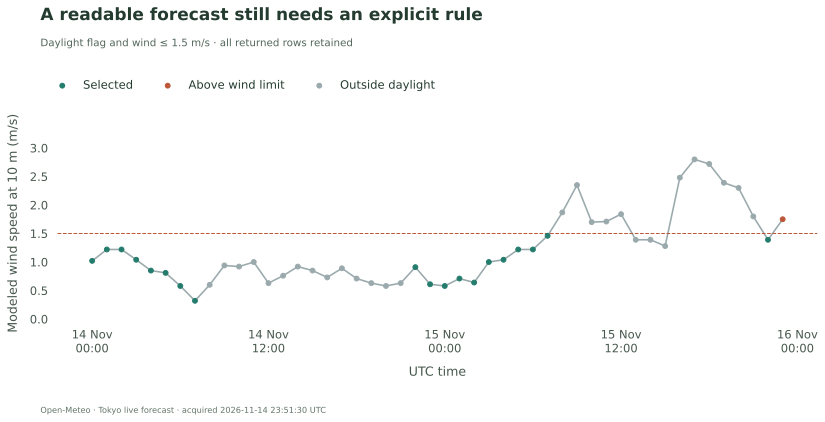

In [16]:
fig, ax = plt.subplots(figsize=(12, 6.2))
times = pd.to_datetime(trace.time, utc=True)
ax.plot(times, trace.wind_speed_10m, color="#9AA9AC", lw=1.6)
for label, color in [("Selected", "#247C6D"), ("Above wind limit", "#BC5738"), ("Outside daylight", "#9AA9AC")]:
    mask = trace.selection.eq(label)
    ax.scatter(times[mask], trace.wind_speed_10m[mask], label=label, color=color, s=24, zorder=3)
ax.axhline(MAX_WIND_MS, color="#BC5738", ls="--", lw=1)
ax.set(ylabel="Modeled wind speed at 10 m (m/s)", xlabel="UTC time", ylim=(0, max(2.2, trace.wind_speed_10m.max()*1.2)))
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0,12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.07,0.83), ncol=3)
finish(fig,"A readable forecast still needs an explicit rule",f"Daylight flag and wind ≤ {MAX_WIND_MS:g} m/s · all returned rows retained",SOURCE,name=f"wind-rule-{MAX_WIND_MS:g}")

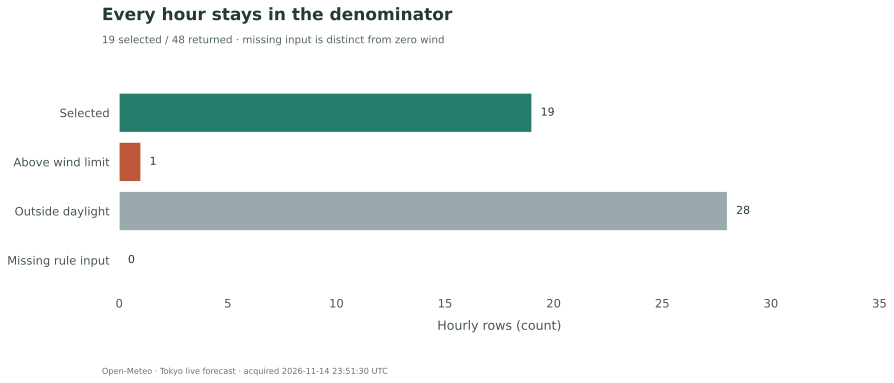

In [17]:
order = ["Selected", "Above wind limit", "Outside daylight", "Missing rule input"]
values = counts.set_index("selection").hours.reindex(order,fill_value=0)
fig, ax = plt.subplots(figsize=(12,5.6))
ax.barh(range(4),values,color=["#247C6D","#BC5738","#9AA9AC","#B68CBA"])
for i, value in enumerate(values): ax.text(value+0.4,i,str(value),va="center")
ax.set_yticks(range(4),order); ax.invert_yaxis()
ax.set(xlabel="Hourly rows (count)",xlim=(0,max(values.max()*1.25,1)))
finish(fig,"Every hour stays in the denominator",f"{int(f.selected_hours)} selected / {int(f.total_hours)} returned · missing input is distinct from zero wind",SOURCE,name=f"selection-counts-{MAX_WIND_MS:g}")

In [18]:
%%sql checks <<
SELECT
  current_setting('TimeZone')='UTC' AS utc_cursor,
 (SELECT count(*)=48 FROM hours) AS two_utc_days,
 (SELECT count(*)=count(DISTINCT time) FROM hours) AS unique_times,
 (SELECT count(*)=count(DISTINCT code) FROM codes) AS unique_lookup_codes,
 (SELECT count(*) FROM decoded)=(SELECT count(*) FROM hours) AS lookup_retains_rows,
 (SELECT bool_and(conditions=lookup_conditions) FROM decoded WHERE lookup_conditions IS NOT NULL) AS macro_matches_reference,
 (SELECT count(*) FILTER(WHERE wind_speed_10m<0)=0 FROM hours) AS nonnegative_wind,
 (SELECT count(*) FILTER(WHERE interval_seconds<>3600)=0 FROM hours) AS hourly_support,
 (SELECT count(*)=1 FROM snapshot) AS one_current_row,
 (SELECT count(*)=1 FROM terrain) AS one_elevation,
 (SELECT count(*) FILTER(WHERE selection='Selected' AND (NOT is_day OR wind_speed_10m>{{MAX_WIND_MS}}))=0 FROM decoded) AS rule_consistent;

In [19]:
display(checks)
if not checks.iloc[0].all(): raise ValueError("Review the weather checks before interpreting the selection.")

,utc_cursor,two_utc_days,unique_times,unique_lookup_codes,lookup_retains_rows,macro_matches_reference,nonnegative_wind,hourly_support,one_current_row,one_elevation,rule_consistent
0,True,True,True,True,True,True,True,True,True,True,True


### Experiment: halve the wind limit

Change only **`MAX_WIND_MS = 0.75`**. Among identical input rows, a stricter limit can only retain or reduce the selection. Check the partition counts and wind chart; weather-code labels and measurements should remain tied to their raw inputs. A live rerun can refresh the forecast, so compare retrieval times before attributing every changed count to the threshold.

```sh
uv run --locked vgi-notebooks 02_weather_codes_and_hourly_selection.ipynb --parameters '{"MAX_WIND_MS":0.75}' --output-dir artifacts/stricter-wind
```

This shows SQL decoding and an explicit rule over modeled weather; it does not validate forecast accuracy. Source: [Open-Meteo forecast API](https://open-meteo.com/en/docs) and [elevation API](https://open-meteo.com/en/docs/elevation-api). Data: Open-Meteo, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

In [20]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-open-meteo](https://github.com/Query-farm/vgi-open-meteo)